In [ ]:
# 1. Necessary libraries for data handling, visualization, and model building.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
# 2. Data Collection and Loading
# Load California Housing dataset
housing = fetch_california_housing()

# Convert to DataFrame
df = pd.DataFrame(housing.data, columns=housing.feature_names)

# Add target variable
df['MedHouseVal'] = housing.target

# Display the dataset
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
# 3. Quick Check of Data:
#3.1 Identify the features and target:
#- Features (independent variables): MedInc, HouseAge, AveRooms, AveBedrms, Population, AveOccup, Latitude, Longitude
#- Target (dependent variable): MedHouseVal
#- The dataset contains numerical continuous variables.
#- There are no categorical variables in the original dataset.

# 3.2 Quick Information on DataFrame
print('info')
df.info()
print('descriptive statistics')
df.describe()

info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
descriptive statistics


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [ ]:
# 4 EDA and Data Preprocessing:
# 4.1 # Check missing values in each column
df.isnull().sum()

,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


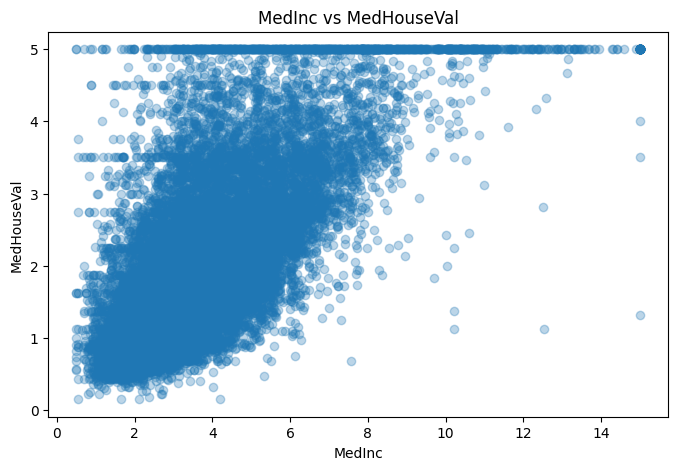

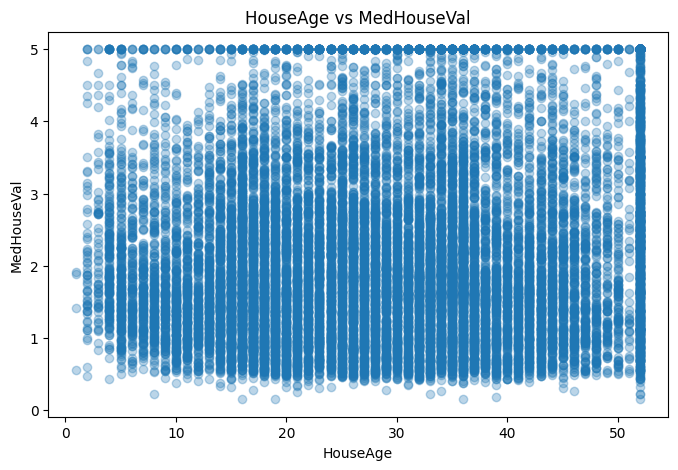

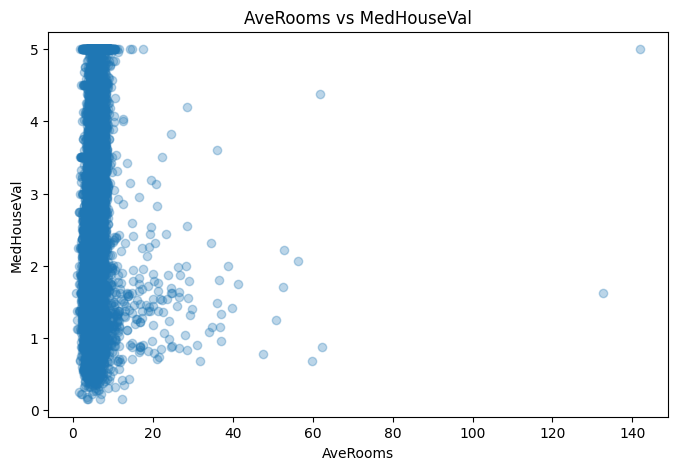

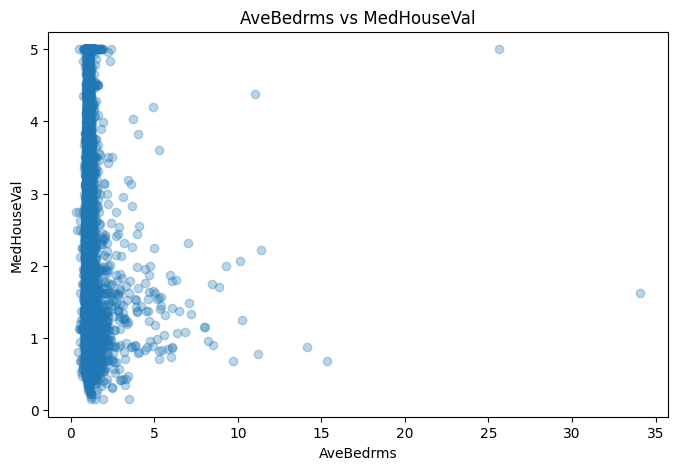

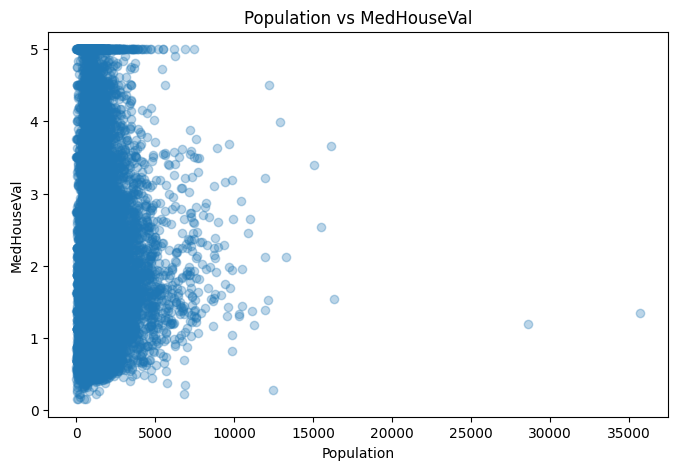

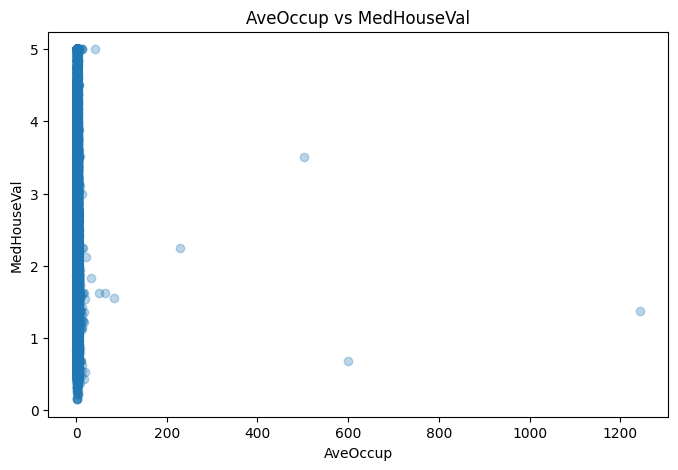

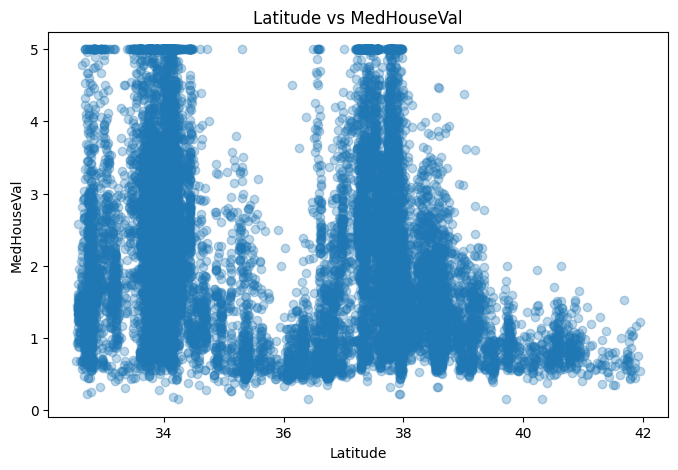

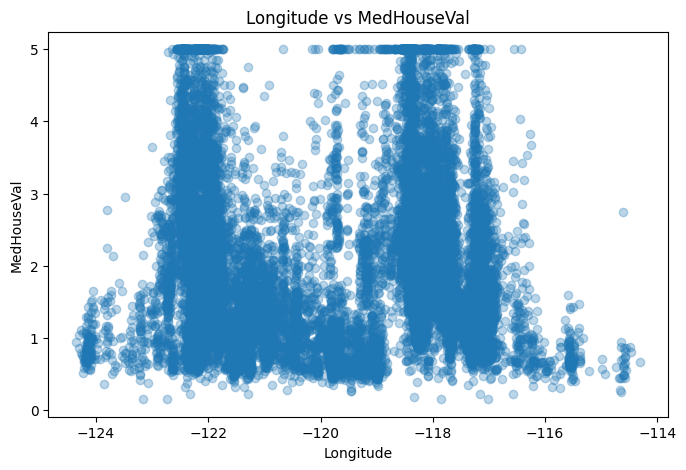

In [ ]:
# 4.2 Visualize the data. scatter plots to see the relationship between independent features and
# the target variable (MedHouseVal)
# Independent features
features = ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms',
            'Population', 'AveOccup', 'Latitude', 'Longitude']

# Create scatter plots
for feature in features:
    plt.figure(figsize=(8, 5))

    plt.scatter(df[feature], df['MedHouseVal'], alpha=0.3)

    plt.xlabel(feature)
    plt.ylabel('MedHouseVal')
    plt.title(f'{feature} vs MedHouseVal')

    plt.show()

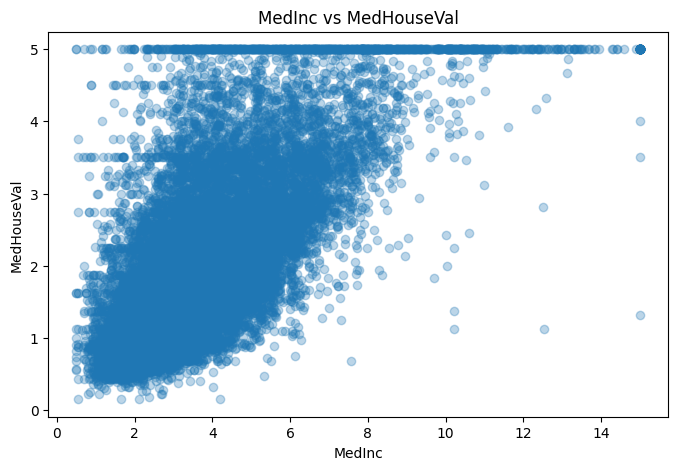

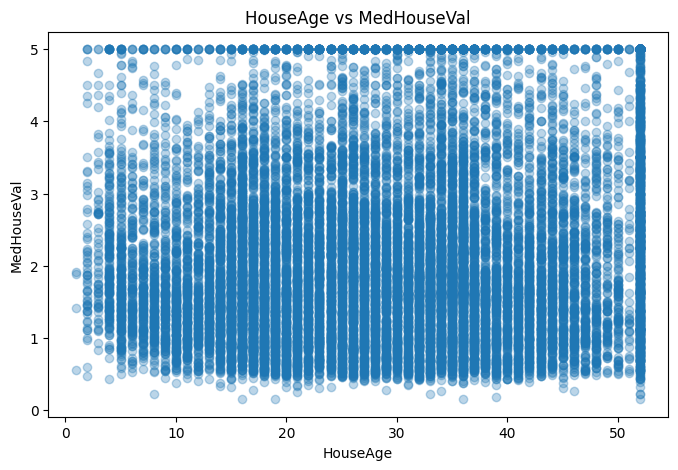

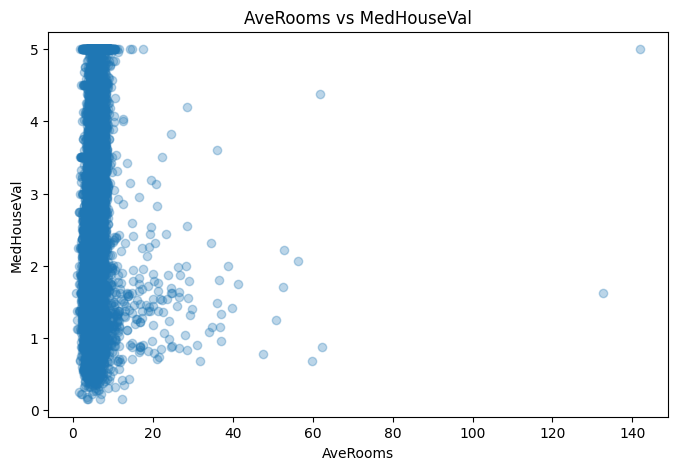

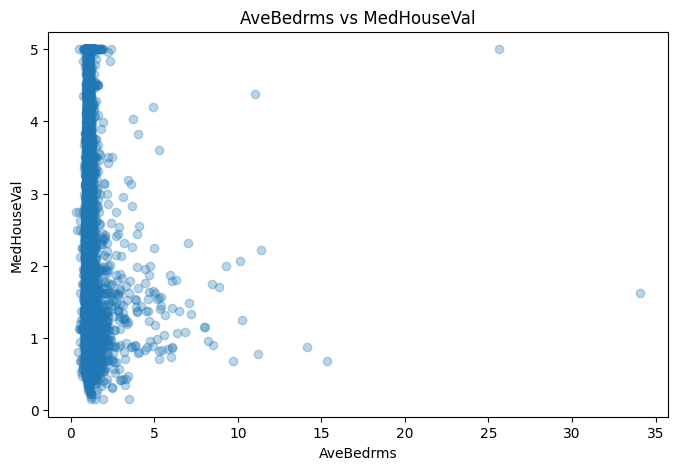

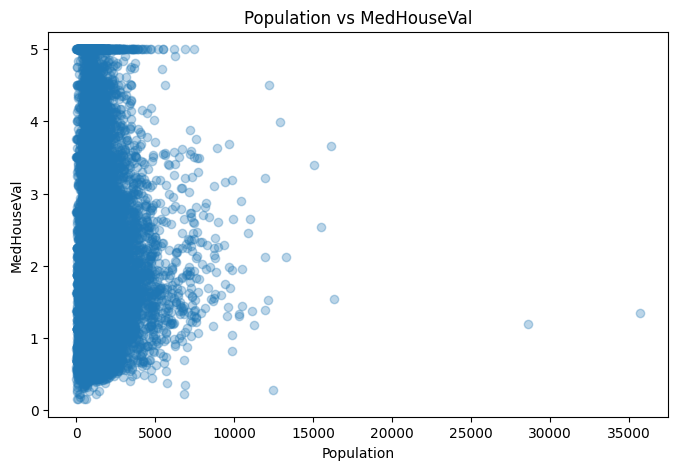

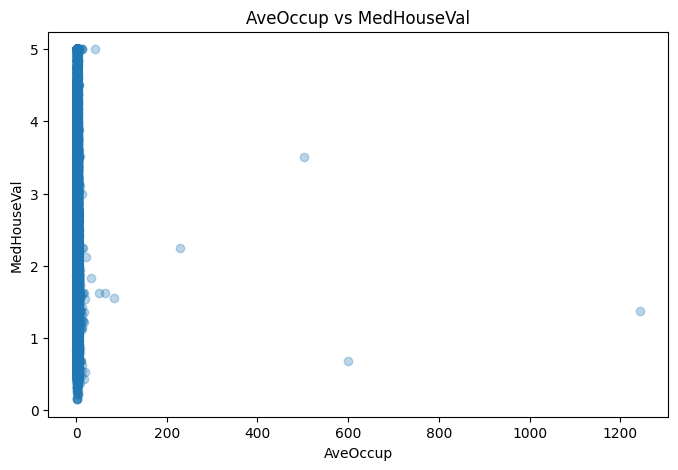

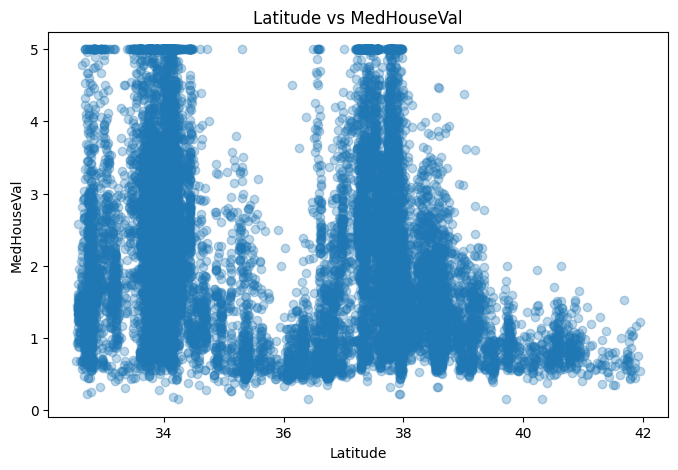

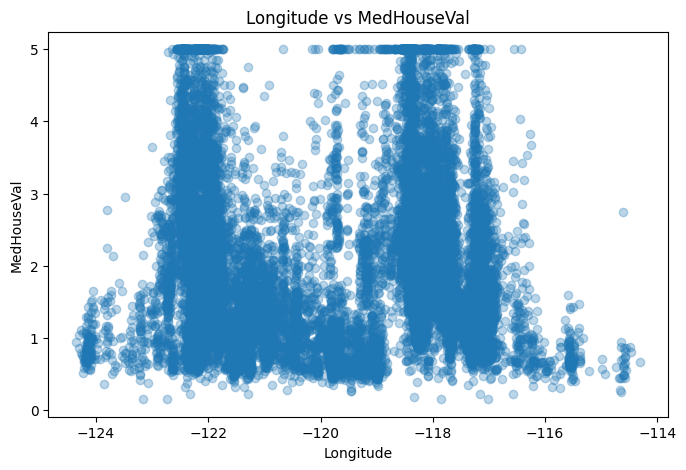

In [ ]:
# Create a function to automate scatter plots for all features vs MedHouseVal
def plot_features(features, target):
    for feature in features:
        plt.figure(figsize=(8, 5))

        plt.scatter(df[feature], df[target], alpha=0.3)

        plt.xlabel(feature)
        plt.ylabel(target)
        plt.title(f'{feature} vs {target}')

        plt.show()


# List of independent features
features = ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms',
            'Population', 'AveOccup', 'Latitude', 'Longitude']

# Target variable
target = 'MedHouseVal'

# Generate scatter plots
plot_features(features, target)

In [ ]:
# 5 ML Model Training:
# 5.1 Split the dataset into training and testing sets.

# 5.11 Separate independent and dependent variables

X = df.drop('MedHouseVal', axis=1)
y = df['MedHouseVal']

#5.12 Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5.13 Display dataset sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("Data split successfully!")


Training features: (16512, 8)
Testing features: (4128, 8)
Training target: (16512,)
Testing target: (4128,)
Data split successfully!


In [ ]:
# 5.2 Choose and train the regression model
model = LinearRegression()
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [ ]:
# 6. Make predictions on the test data
# 6.1 # Predict house values using the test data
y_pred = model.predict(X_test)

print("Predictions completed successfully!")

Predictions completed successfully!


In [ ]:
# 6.2 Calculate Mean Squared Error
mse = mean_squared_error(y_test, y_pred)

# Calculate Root Mean Squared Error
rmse = np.sqrt(mse)

# Calculate R-squared
r2 = r2_score(y_test, y_pred)

# Display results
print("Model Evaluation Results")
print("-------------------------")
print("Mean Squared Error (MSE):", round(mse, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))
print("R-squared (R²):", round(r2, 4))

Model Evaluation Results
-------------------------
Mean Squared Error (MSE): 0.5559
Root Mean Squared Error (RMSE): 0.7456
R-squared (R²): 0.5758


In [ ]:
# 7 Model Prediction:
# 7.1  Predict Median House Value from a new set of feature inputs.
# Create new house feature inputs
new_house = pd.DataFrame({
    'MedInc': [3.5],
    'HouseAge': [25],
    'AveRooms': [5.5],
    'AveBedrms': [1.2],
    'Population': [1200],
    'AveOccup': [3],
    'Latitude': [34.05],
    'Longitude': [-118.25]
})

# Display new house information
print("New House Features:")
display(new_house)




New House Features:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,3.5,25,5.5,1.2,1200,3,34.05,-118.25


In [ ]:
# 7.2 Predict the median house value
predicted_value = model.predict(new_house)

# Display prediction
print("Predicted Median House Value:", round(predicted_value[0], 4))

Predicted Median House Value: 2.0307
